# Task 3: Linear Regression

**Objective:** Implement simple and multiple linear regression to understand relationships between housing features and house prices and make price predictions.

**Dataset:** Housing Price Prediction Dataset (`Housing.csv`).

**Dataset Size:** 545 records and 13 columns.

**Tools:** Python, Pandas, Matplotlib and Scikit-learn.



# **1.Import and preprocess the dataset.**

In [3]:
#Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import LabelEncoder

In [4]:
#Upload Housing Dataset

from google.colab import files

uploaded = files.upload()

Saving Housing.csv to Housing.csv


In [5]:
#Read the Dataset

df = pd.read_csv("Housing.csv")

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [6]:
#Check Dataset Information

print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

Dataset Shape: (545, 13)

Column Names:
Index(['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad',
       'guestroom', 'basement', 'hotwaterheating', 'airconditioning',
       'parking', 'prefarea', 'furnishingstatus'],
      dtype='object')

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype 
---  ------            --------------  ----- 
 0   price             545 non-null    int64 
 1   area              545 non-null    int64 
 2   bedrooms          545 non-null    int64 
 3   bathrooms         545 non-null    int64 
 4   stories           545 non-null    int64 
 5   mainroad          545 non-null    object
 6   guestroom         545 non-null    object
 7   basement          545 non-null    object
 8   hotwaterheating   545 non-null    object
 9   airconditioning   545 non-null    object
 10  parking           545 non-null    int64 
 11  prefarea       

In [7]:
#Check Missing Values

print(df.isnull().sum())

price               0
area                0
bedrooms            0
bathrooms           0
stories             0
mainroad            0
guestroom           0
basement            0
hotwaterheating     0
airconditioning     0
parking             0
prefarea            0
furnishingstatus    0
dtype: int64


In [8]:
#Check Duplicate Records

print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


Because the Housing dataset contains text values such as:

- `yes` / `no`
- `furnished` / `semi-furnished` / `unfurnished`

Linear Regression works with numerical input, so LabelEncoder converts these text categories into numbers.

For example:

| Original value | Encoded value |
| -------------- | ------------- |
| yes            | 1             |
| no             | 0             |
| furnished      | 0             |
| semi-furnished | 1             |
| unfurnished    | 2             |

In short: We encode categorical features so the regression model can process them mathematically.

In [9]:
#Encode Categorical Features

le = LabelEncoder()

df["mainroad"] = le.fit_transform(df["mainroad"])
df["guestroom"] = le.fit_transform(df["guestroom"])
df["basement"] = le.fit_transform(df["basement"])
df["hotwaterheating"] = le.fit_transform(df["hotwaterheating"])
df["airconditioning"] = le.fit_transform(df["airconditioning"])
df["prefarea"] = le.fit_transform(df["prefarea"])
df["furnishingstatus"] = le.fit_transform(df["furnishingstatus"])

df.head()

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,1,0,0,0,1,2,1,0
1,12250000,8960,4,4,4,1,0,0,0,1,3,0,0
2,12250000,9960,3,2,2,1,0,1,0,0,2,1,1
3,12215000,7500,4,2,2,1,0,1,0,1,3,1,0
4,11410000,7420,4,1,2,1,1,1,0,1,2,0,0


# **2.Split data into train-test sets.**

X contains all input features used to predict house prices.



y contains the target column (price) that we want to predict.

In [10]:
#Separate Input and Output Features

X = df.drop("price", axis=1)

y = df["price"]

print("Input Features:")
print(X.head())

print("\nTarget Feature:")
print(y.head())

Input Features:
   area  bedrooms  bathrooms  stories  mainroad  guestroom  basement  \
0  7420         4          2        3         1          0         0   
1  8960         4          4        4         1          0         0   
2  9960         3          2        2         1          0         1   
3  7500         4          2        2         1          0         1   
4  7420         4          1        2         1          1         1   

   hotwaterheating  airconditioning  parking  prefarea  furnishingstatus  
0                0                1        2         1                 0  
1                0                1        3         0                 0  
2                0                0        2         1                 1  
3                0                1        3         1                 0  
4                0                1        2         0                 0  

Target Feature:
0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, d

80% of the data is used for training.



20% of the data is used for testing.



random_state=42 ensures a consistent split when you run the code again.



In [11]:
#Split Data into Training and Testing Sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training Data:", X_train.shape)

print("Testing Data:", X_test.shape)

Training Data: (436, 12)
Testing Data: (109, 12)


# **3.Fit a Linear Regression model using sklearn.linear_model.**

LinearRegression() creates a linear regression model.



model.fit() trains the model using training data.



X_train contains input features.



y_train contains actual house prices.

The model learns the relationship between housing features and house prices so that it can predict prices for new data.

In [14]:
#Train Linear Regression Model

model = LinearRegression()

model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


# **4.Evaluate model using MAE, MSE, R².**

In [15]:
#Predict House Prices
y_pred = model.predict(X_test)

print("Predicted House Prices:")
print(y_pred[:10])

Predicted House Prices:
[5203691.70963178 7257004.02115475 3062828.59668171 4559591.65374424
 3332932.30559782 3563080.67918997 5645466.31219972 6413979.66873635
 2755831.54819    2668938.66075228]


In [16]:
#Evaluate Linear Regression Model

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

r2 = r2_score(y_test, y_pred)

print("Mean Absolute Error:", mae)
print("Mean Squared Error:", mse)
print("R2 Score:", r2)

Mean Absolute Error: 979679.6912959901
Mean Squared Error: 1771751116594.0352
R2 Score: 0.6494754192267803


### Understanding Evaluation Metrics

| Metric | Meaning |
|---|---|
| **MAE (Mean Absolute Error)** | Average absolute difference between actual and predicted prices. |
| **MSE (Mean Squared Error)** | Average squared prediction error. |
| **R² Score** | Measures how well the model explains variations in house prices. |

### Model Evaluation

- **Lower MAE:** Better predictions.
- **Lower MSE:** Smaller squared errors.
- **R² closer to 1:** Better model fit.

### Model Evaluation Results

| Evaluation Metric | Result |
|---|---:|
| Mean Absolute Error (MAE) | 979,679.69 |
| Mean Squared Error (MSE) | 1,771,751,116,594.04 |
| R² Score | 0.6495 (64.95%) |

### Performance Analysis

- **MAE:** The average prediction error is approximately 979,679.69.
- **MSE:** Measures the average squared difference between actual and predicted house prices.
- **R² Score:** The model explains approximately 64.95% of the variation in house prices.

**Conclusion:** The Linear Regression model achieved an R² score of 64.95%, showing that it can explain a reasonable portion of house price variations. There is still scope to improve prediction accuracy.

In [17]:
#Compare Actual and Predicted Prices

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0       4060000     5.203692e+06
1       6650000     7.257004e+06
2       3710000     3.062829e+06
3       6440000     4.559592e+06
4       2800000     3.332932e+06
5       4900000     3.563081e+06
6       5250000     5.645466e+06
7       4543000     6.413980e+06
8       2450000     2.755832e+06
9       3353000     2.668939e+06


# **5.Plot regression line and interpret coefficients.**

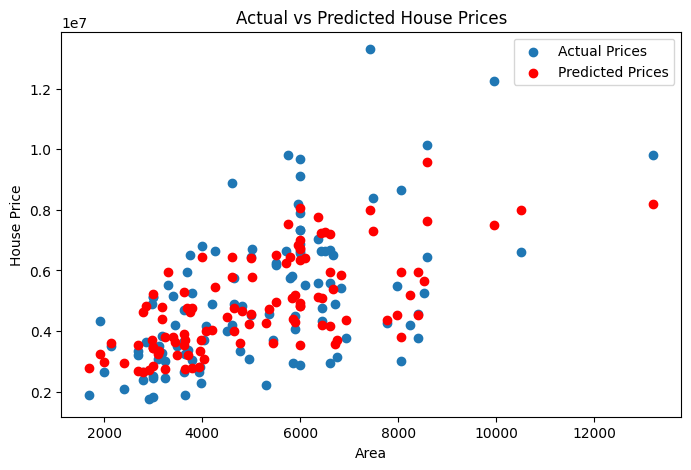

In [18]:
#Plot Regression Line

plt.figure(figsize=(8, 5))

plt.scatter(X_test["area"], y_test, label="Actual Prices")

plt.scatter(X_test["area"], y_pred, color="red", label="Predicted Prices")

plt.xlabel("Area")

plt.ylabel("House Price")

plt.title("Actual vs Predicted House Prices")

plt.legend()

plt.show()

In [19]:
#Display Model Coefficients

print("Intercept:", model.intercept_)

print("\nCoefficients:")

for feature, coefficient in zip(X.columns, model.coef_):
    print(feature, ":", coefficient)

Intercept: 293083.06915066857

Coefficients:
area : 235.84877178813724
bedrooms : 78574.49238760071
bathrooms : 1097117.2661479574
stories : 406223.16446288454
mainroad : 366824.1923924831
guestroom : 233146.76562655077
basement : 393159.7787258404
hotwaterheating : 687881.3109570158
airconditioning : 785550.5792954286
parking : 225756.5139762815
prefarea : 629901.6608459124
furnishingstatus : -210397.11827155566


Regression Line Plot and Coefficient Interpretation

In this step, I plotted the actual and predicted house prices using a scatter plot to understand the performance of the Linear Regression model.

**Coefficient Analysis:**

After training the model, I obtained the intercept and coefficients for all the input features. From the results, I observed that:

- **Area (235.85):** An increase in house area is associated with an increase in predicted house price.
- **Bedrooms (78,574.49):** The number of bedrooms has a positive relationship with predicted price.
- **Bathrooms (1,097,117.27):** Bathrooms have a positive coefficient in the model.
- **Stories (406,223.16):** The number of stories contributes positively to the predicted price.
- **Mainroad, Guestroom and Basement:** These features have positive coefficients.
- **Hot Water Heating and Air Conditioning:** Both features have positive coefficients.
- **Parking and Preferred Area:** These features also show positive coefficients.
- **Furnishing Status (-210,397.12):** This feature has a negative coefficient based on its numerical encoding.

The model intercept is **293,083.07**.

**Graph Interpretation:**

The scatter plot compares actual house prices (blue points) with predicted house prices (red points). The graph shows a general increasing relationship between house area and price. However, some differences between actual and predicted values can also be observed.

**Conclusion:**

Through this analysis, I understood how different housing features contribute to house price predictions. The coefficient values helped me interpret the relationship between input features and the target variable, while the scatter plot helped me visually compare actual and predicted prices. The model achieved an R² score of **0.6495 (64.95%)**.

In [20]:
#Interpret Model Coefficients

for feature, coefficient in zip(X.columns, model.coef_):

    if coefficient > 0:
        print(feature, "has a positive effect on house price.")

    else:
        print(feature, "has a negative effect on house price.")

area has a positive effect on house price.
bedrooms has a positive effect on house price.
bathrooms has a positive effect on house price.
stories has a positive effect on house price.
mainroad has a positive effect on house price.
guestroom has a positive effect on house price.
basement has a positive effect on house price.
hotwaterheating has a positive effect on house price.
airconditioning has a positive effect on house price.
parking has a positive effect on house price.
prefarea has a positive effect on house price.
furnishingstatus has a negative effect on house price.
